## 2. Dataset Loading and Shared Train/Test Split

**Objective:** To load the Credit Card Default dataset and apply the shared stratified 80/20 train/test split provided by M2.

**Evidence:** Dataset and split dimensions.

**Report Section:** Chapter 2.1 and Chapter 3.2.

In [3]:
import os
import sys
from pathlib import Path

print("Current folder:", Path.cwd())

# Find the project root containing src/preprocessing.py
project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src" / "preprocessing.py").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Cannot find src/preprocessing.py. "
        "Please check your VS Code project folder."
    )

sys.path.insert(0, str(project_root))
os.chdir(project_root)

print("Project root:", project_root)
print("Ready!")

Current folder: c:\Users\Vivian\OneDrive\Documents\A 6001CMD Machine learning\ML Group\notebooks
Project root: c:\Users\Vivian\OneDrive\Documents\A 6001CMD Machine learning\ML Group
Ready!


In [4]:
from src.preprocessing import load_data, split_data

df = load_data()

X_train, X_test, y_train, y_test = split_data(df)

print("Full dataset:", df.shape)
print("Training data:", X_train.shape)
print("Test data:", X_test.shape)

display(X_train.describe().T)

Full dataset: (30000, 25)
Training data: (24000, 23)
Test data: (6000, 23)


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,24000.0,167364.666667,129511.313151,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,24000.0,1.604750,0.488915,1.0,1.00,2.0,2.00,2.0
EDUCATION,24000.0,1.853792,0.792375,0.0,1.00,2.0,2.00,6.0
MARRIAGE,24000.0,1.552875,0.521903,0.0,1.00,2.0,2.00,3.0
AGE,24000.0,35.432625,9.195256,21.0,28.00,34.0,41.00,75.0
PAY_0,24000.0,-0.014125,1.123155,-2.0,-1.00,0.0,0.00,8.0
PAY_2,24000.0,-0.134083,1.198818,-2.0,-1.00,0.0,0.00,8.0
PAY_3,24000.0,-0.166917,1.194166,-2.0,-1.00,0.0,0.00,8.0
PAY_4,24000.0,-0.221333,1.161924,-2.0,-1.00,0.0,0.00,8.0
PAY_5,24000.0,-0.270333,1.125192,-2.0,-1.00,0.0,0.00,8.0


Descriptive Statistics

**Objective:** To summarise the distribution and variability of numerical features in the training dataset.

**Output:** `results/eda_descriptive_statistics.csv`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Descriptive statistics for training features
stats = X_train.describe().T

display(stats)

# Save evidence
from pathlib import Path

Path("results").mkdir(exist_ok=True)
stats.to_csv("results/eda_descriptive_statistics.csv")

print("Saved: results/eda_descriptive_statistics.csv")

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,24000.0,167364.666667,129511.313151,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,24000.0,1.604750,0.488915,1.0,1.00,2.0,2.00,2.0
EDUCATION,24000.0,1.853792,0.792375,0.0,1.00,2.0,2.00,6.0
MARRIAGE,24000.0,1.552875,0.521903,0.0,1.00,2.0,2.00,3.0
AGE,24000.0,35.432625,9.195256,21.0,28.00,34.0,41.00,75.0
PAY_0,24000.0,-0.014125,1.123155,-2.0,-1.00,0.0,0.00,8.0
PAY_2,24000.0,-0.134083,1.198818,-2.0,-1.00,0.0,0.00,8.0
PAY_3,24000.0,-0.166917,1.194166,-2.0,-1.00,0.0,0.00,8.0
PAY_4,24000.0,-0.221333,1.161924,-2.0,-1.00,0.0,0.00,8.0
PAY_5,24000.0,-0.270333,1.125192,-2.0,-1.00,0.0,0.00,8.0


Saved: results/eda_descriptive_statistics.csv


## 4. Target Class Distribution

**Objective:** To examine the proportion of default and non-default cases in the training dataset and identify potential class imbalance.

**Evidence:** `figures/eda_target_distribution.png`

**Report Section:** Chapter 2.1 — Dataset Overview and Data Quality Analysis.

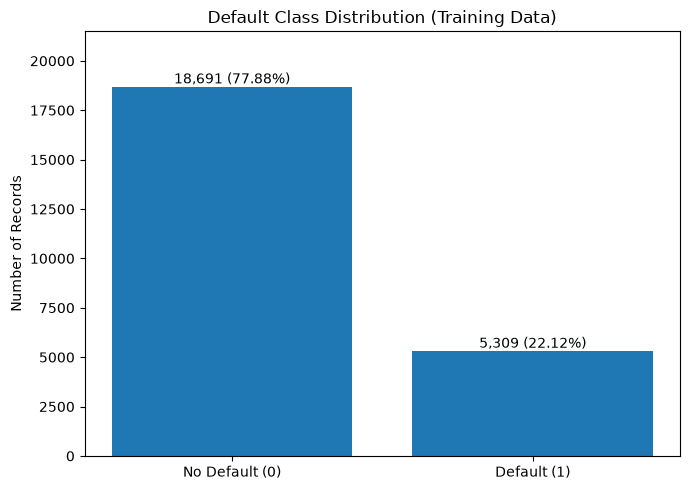

Saved: figures/eda_target_distribution.png


In [6]:
from pathlib import Path
import matplotlib.pyplot as plt

# Use training labels for EDA
counts = y_train.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["No Default (0)", "Default (1)"],
    counts.values
)

ax.set_title("Default Class Distribution (Training Data)")
ax.set_ylabel("Number of Records")

for bar, count in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,} ({count / len(y_train):.2%})",
        ha="center",
        va="bottom"
    )

ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/eda_target_distribution.png", dpi=300)
plt.show()

print("Saved: figures/eda_target_distribution.png")

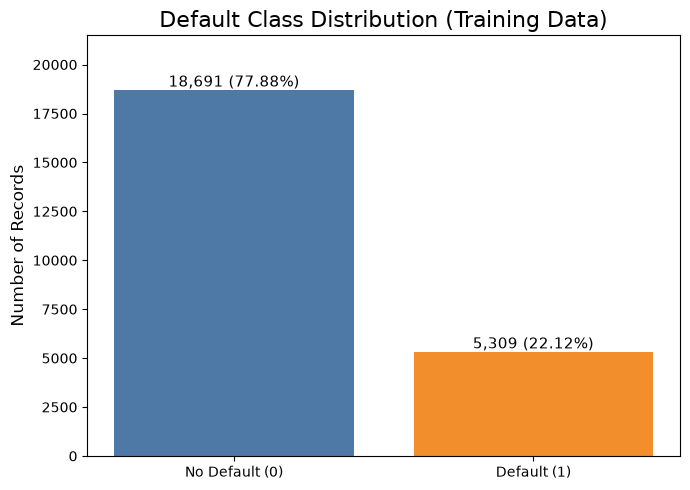

Saved: figures/eda_target_distribution.png


In [10]:
from pathlib import Path
import matplotlib.pyplot as plt

counts = y_train.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["No Default (0)", "Default (1)"],
    counts.values,
    color=["#4E79A7", "#F28E2B"]
)

ax.set_title("Default Class Distribution (Training Data)", fontsize=16)
ax.set_ylabel("Number of Records", fontsize=12)

for bar, count in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,} ({count / len(y_train):.2%})",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/eda_target_distribution.png", dpi=300)
plt.show()

print("Saved: figures/eda_target_distribution.png")

## 5. Credit Limit Distribution

**Objective:** To examine the distribution of credit limits among customers and identify potential skewness and extreme values.

**Feature:** LIMIT_BAL

**Evidence:** `figures/eda_credit_limit_distribution.png`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation

Credit Limit Statistics
Mean: 167364.67
Median: 140000.0
Minimum: 10000
Maximum: 1000000
Skewness: 1.0


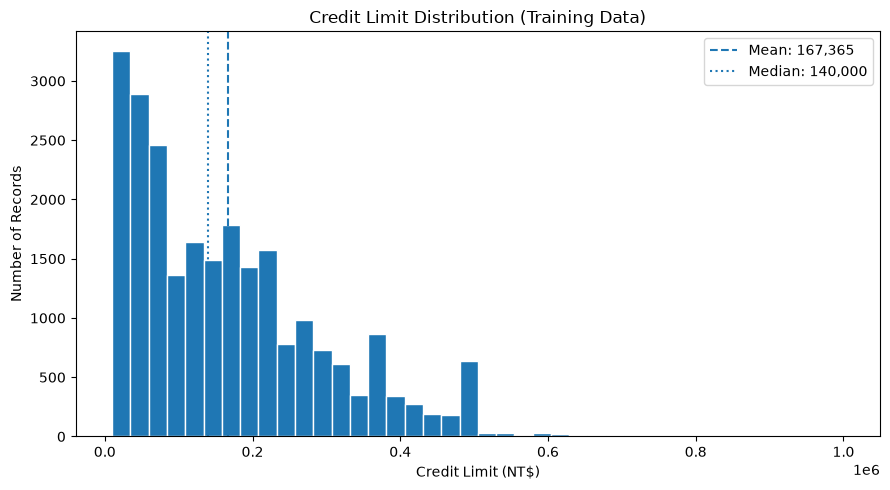

Saved: figures/eda_credit_limit_distribution.png


In [7]:
from pathlib import Path
import matplotlib.pyplot as plt

# Use training features only
credit_limit = X_train["LIMIT_BAL"]

# Calculate descriptive statistics
print("Credit Limit Statistics")
print("Mean:", round(credit_limit.mean(), 2))
print("Median:", round(credit_limit.median(), 2))
print("Minimum:", credit_limit.min())
print("Maximum:", credit_limit.max())
print("Skewness:", round(credit_limit.skew(), 3))

# Visualise the distribution
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    credit_limit,
    bins=40,
    edgecolor="white"
)

ax.axvline(
    credit_limit.mean(),
    linestyle="--",
    label=f"Mean: {credit_limit.mean():,.0f}"
)

ax.axvline(
    credit_limit.median(),
    linestyle=":",
    label=f"Median: {credit_limit.median():,.0f}"
)

ax.set_title("Credit Limit Distribution (Training Data)")
ax.set_xlabel("Credit Limit (NT$)")
ax.set_ylabel("Number of Records")
ax.legend()

plt.tight_layout()

# Save figure
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_credit_limit_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: figures/eda_credit_limit_distribution.png")

### Findings — Credit Limit Distribution

The distribution of credit limits is positively skewed (skewness = 1.0). The mean credit limit (NT$167,364.67) is higher than the median (NT$140,000), indicating that relatively high credit limits influence the overall average. A small number of records have substantially higher credit limits, with the maximum reaching NT$1,000,000. These observations suggest that credit limits vary considerably across customers.

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.


## 6. Age Distribution

**Objective:** To examine the age distribution of credit card customers and identify the typical age range, skewness, and potential extreme values.

**Feature:** AGE

**Evidence:** `figures/eda_age_distribution.png`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.


Age Statistics
Mean: 35.43
Median: 34.0
Minimum: 21
Maximum: 75
Standard Deviation: 9.2
Skewness: 0.738


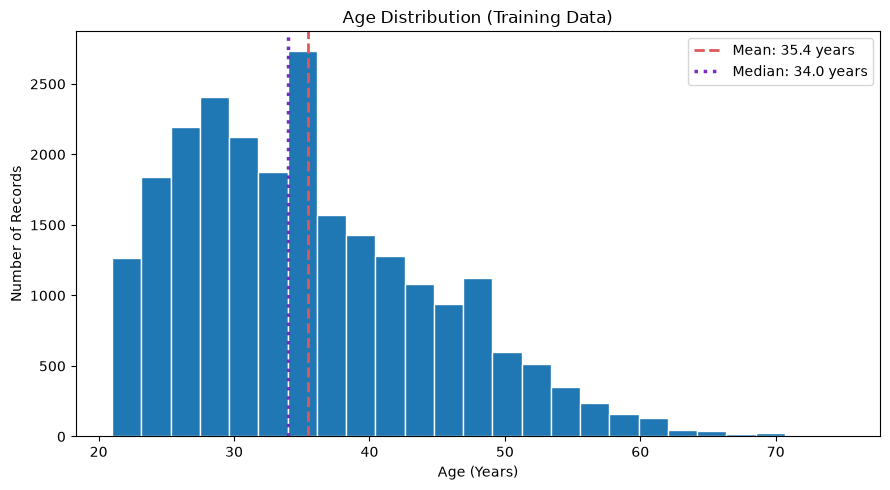

Saved: figures/eda_age_distribution.png


In [14]:
from pathlib import Path
import matplotlib.pyplot as plt

# Use training data only
age = X_train["AGE"]

# Calculate age statistics
print("Age Statistics")
print("Mean:", round(age.mean(), 2))
print("Median:", age.median())
print("Minimum:", age.min())
print("Maximum:", age.max())
print("Standard Deviation:", round(age.std(), 2))
print("Skewness:", round(age.skew(), 3))

# Plot age distribution
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    age,
    bins=25,
    edgecolor="white"
)

# Mean and median reference lines
ax.axvline(
    age.mean(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {age.mean():.1f} years"
)

ax.axvline(
    age.median(),
    color="#7B2CBF",
    linestyle=":",
    linewidth=2.5,
    label=f"Median: {age.median():.1f} years"
)

ax.set_title("Age Distribution (Training Data)")
ax.set_xlabel("Age (Years)")
ax.set_ylabel("Number of Records")
ax.legend()

plt.tight_layout()

# Save figure
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: figures/eda_age_distribution.png")

Age Statistics
Mean: 35.43
Median: 34.0
Minimum: 21
Maximum: 75
Standard Deviation: 9.2
Skewness: 0.738


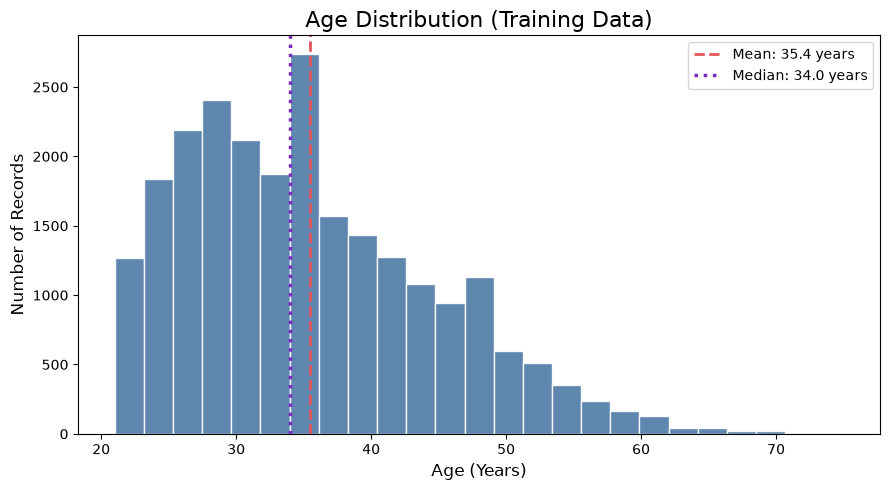

Saved: figures/eda_age_distribution.png


In [12]:
from pathlib import Path
import matplotlib.pyplot as plt

age = X_train["AGE"]

print("Age Statistics")
print("Mean:", round(age.mean(), 2))
print("Median:", age.median())
print("Minimum:", age.min())
print("Maximum:", age.max())
print("Standard Deviation:", round(age.std(), 2))
print("Skewness:", round(age.skew(), 3))

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    age,
    bins=25,
    color="#4E79A7",
    edgecolor="white",
    alpha=0.9
)

ax.axvline(
    age.mean(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {age.mean():.1f} years"
)

ax.axvline(
    age.median(),
    color="#7B2CBF",
    linestyle=":",
    linewidth=2.5,
    label=f"Median: {age.median():.1f} years"
)

ax.set_title("Age Distribution (Training Data)", fontsize=16)
ax.set_xlabel("Age (Years)", fontsize=12)
ax.set_ylabel("Number of Records", fontsize=12)
ax.legend()

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig(
    "figures/eda_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: figures/eda_age_distribution.png")

### Findings — Age Distribution

The age distribution is moderately right-skewed (skewness = 0.738), with a mean age of 35.43 years and a median of 34 years. Most customers are concentrated in early to middle adulthood, while relatively fewer customers belong to older age groups. The observed ages range from 21 to 75 years.

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.

Credit Limit Statistics
Mean: 167364.67
Median: 140000.0
Minimum: 10000
Maximum: 1000000
Skewness: 1.0


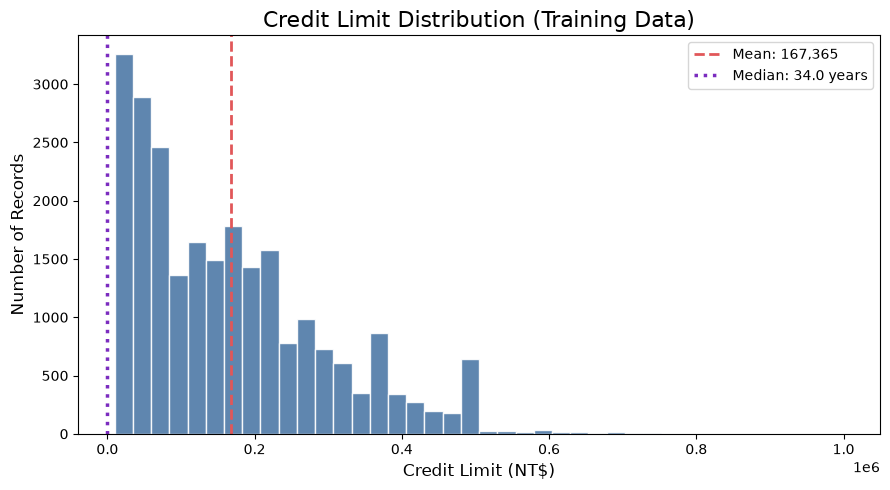

Saved: figures/eda_credit_limit_distribution.png


In [15]:
from pathlib import Path
import matplotlib.pyplot as plt

credit_limit = X_train["LIMIT_BAL"]

print("Credit Limit Statistics")
print("Mean:", round(credit_limit.mean(), 2))
print("Median:", round(credit_limit.median(), 2))
print("Minimum:", credit_limit.min())
print("Maximum:", credit_limit.max())
print("Skewness:", round(credit_limit.skew(), 3))

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    credit_limit,
    bins=40,
    color="#4E79A7",
    edgecolor="white",
    alpha=0.9
)

ax.axvline(
    credit_limit.mean(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {credit_limit.mean():,.0f}"
)

ax.axvline(
    age.median(),
    color="#7B2CBF",
    linestyle=":",
    linewidth=2.5,
    label=f"Median: {age.median():.1f} years"
)

ax.set_title("Credit Limit Distribution (Training Data)", fontsize=16)
ax.set_xlabel("Credit Limit (NT$)", fontsize=12)
ax.set_ylabel("Number of Records", fontsize=12)
ax.legend()

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig(
    "figures/eda_credit_limit_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: figures/eda_credit_limit_distribution.png")

## 7. Repayment Status Analysis

**Objective:** To analyse the distribution of repayment status (PAY_0) and examine its relationship with credit card default.

**Feature:** PAY_0

**Evidence:**
- `figures/eda_repayment_status_analysis.png`
- `results/eda_repayment_status_summary.csv`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation

**Note:** Only training data is used to examine feature–target relationships and avoid influencing modelling decisions using the held-out test set.

,records,defaults,default_rate,default_rate_pct
PAY_0,,,,
-2,2198,279,0.126934,12.693358
-1,4527,753,0.166335,16.633532
0,11781,1508,0.128003,12.800272
1,3000,1031,0.343667,34.366667
2,2138,1483,0.693639,69.363891
3,245,188,0.767347,76.734694
4,58,38,0.655172,65.517241
5,18,8,0.444444,44.444444
6,10,6,0.600000,60.000000


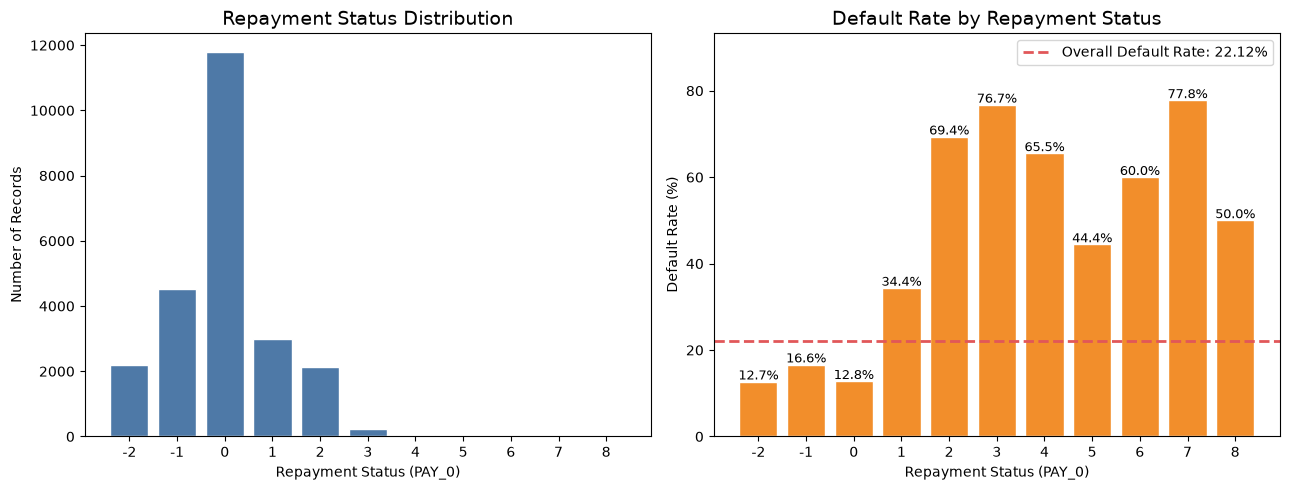

Saved: figures/eda_repayment_status_analysis.png
Saved: results/eda_repayment_status_summary.csv


In [16]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# 1. Combine training feature and target
repayment_df = X_train[["PAY_0"]].copy()
repayment_df["default_next_month"] = y_train

# 2. Calculate repayment status statistics
summary = (
    repayment_df.groupby("PAY_0")["default_next_month"]
    .agg(["size", "sum", "mean"])
    .rename(columns={
        "size": "records",
        "sum": "defaults",
        "mean": "default_rate"
    })
    .sort_index()
)

summary["default_rate_pct"] = summary["default_rate"] * 100

display(summary)

# 3. Prepare figure
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

status_labels = summary.index.astype(str)

# Left: Number of customers
axes[0].bar(
    status_labels,
    summary["records"],
    color="#4E79A7",
    edgecolor="white"
)

axes[0].set_title(
    "Repayment Status Distribution",
    fontsize=14
)
axes[0].set_xlabel("Repayment Status (PAY_0)")
axes[0].set_ylabel("Number of Records")

# Right: Default rate by repayment status
bars = axes[1].bar(
    status_labels,
    summary["default_rate_pct"],
    color="#F28E2B",
    edgecolor="white"
)

# Overall training default rate
overall_rate = y_train.mean() * 100

axes[1].axhline(
    overall_rate,
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Overall Default Rate: {overall_rate:.2f}%"
)

axes[1].set_title(
    "Default Rate by Repayment Status",
    fontsize=14
)
axes[1].set_xlabel("Repayment Status (PAY_0)")
axes[1].set_ylabel("Default Rate (%)")
axes[1].legend()

axes[1].set_ylim(
    0,
    max(summary["default_rate_pct"].max() * 1.2, 5)
)

# Add percentage labels
for bar, rate in zip(bars, summary["default_rate_pct"]):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{rate:.1f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

# 4. Save evidence
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_repayment_status_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

summary.to_csv(
    "results/eda_repayment_status_summary.csv"
)

plt.show()

print("Saved: figures/eda_repayment_status_analysis.png")
print("Saved: results/eda_repayment_status_summary.csv")

### Findings — Repayment Status Analysis

The analysis indicates a strong association between repayment status (PAY_0) and credit card default. Customers with PAY_0 = 0 account for the largest group (11,781 records) and have a default rate of 12.80%, which is below the overall training default rate of 22.12%.

In contrast, the default rate increases to 34.37% for PAY_0 = 1 and 69.36% for PAY_0 = 2. PAY_0 = 3 also shows a high default rate of 76.73%. These findings suggest that repayment status may be an informative predictor of default.

However, higher repayment-status categories contain relatively few observations. Their default rates should therefore be interpreted cautiously due to limited sample sizes. The observed relationship is descriptive and does not establish causation.

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.

## 8. Bill and Payment Amount Analysis

**Objective:** To examine the distributions and variability of billing and payment amounts across six recorded periods.

**Features:** BILL_AMT1–6 and PAY_AMT1–6

**Evidence:**
- `results/eda_bill_payment_summary.csv`
- `figures/eda_bill_payment_distribution.png`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation

**Note:** The histograms display the 1st–99th percentile range for readability. Full training data is retained for statistical calculations.

,mean,median,std,min,max,zero_count,negative_count
BILL_AMT1,51100.50,22330.0,73510.03,-165580.0,964511.0,1612,468
BILL_AMT2,49012.27,21107.0,70840.10,-69777.0,983931.0,1986,522
BILL_AMT3,46861.88,20031.0,68403.93,-61506.0,855086.0,2308,515
BILL_AMT4,43156.66,19004.5,64046.73,-81334.0,891586.0,2555,530
BILL_AMT5,40164.41,18102.5,60627.85,-81334.0,927171.0,2828,524
BILL_AMT6,38675.98,16993.0,59308.74,-339603.0,961664.0,3223,556
PAY_AMT1,5623.56,2100.5,16148.32,0.0,873552.0,4180,0
PAY_AMT2,5879.97,2014.0,20252.98,0.0,1215471.0,4324,0
PAY_AMT3,5215.78,1805.5,17513.55,0.0,896040.0,4780,0
PAY_AMT4,4790.33,1500.0,15060.69,0.0,621000.0,5141,0


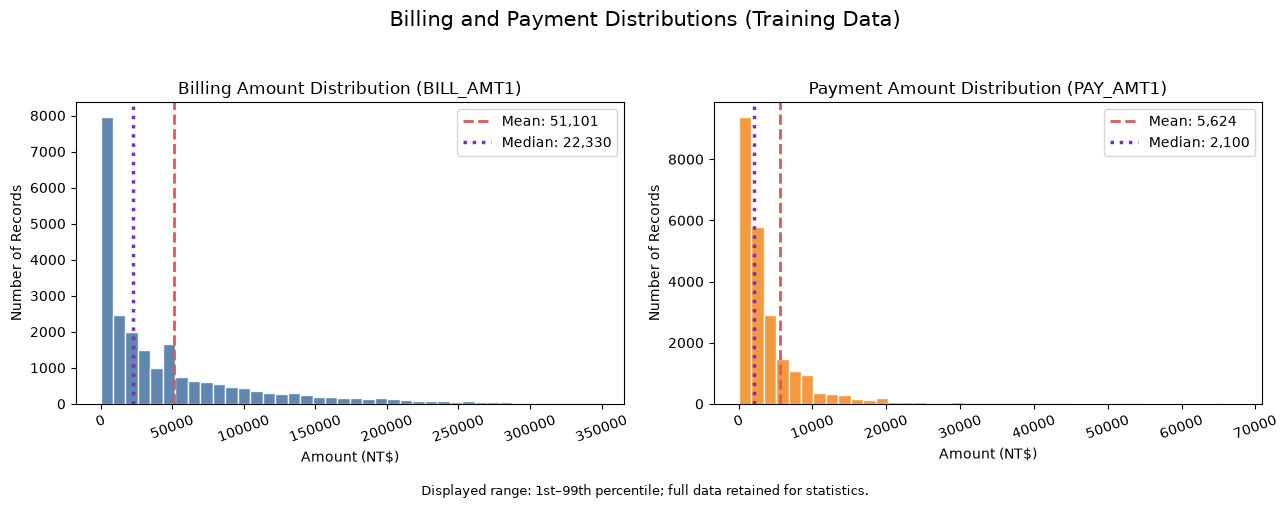

Saved: results/eda_bill_payment_summary.csv
Saved: figures/eda_bill_payment_distribution.png


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Select billing and payment features
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

# 2. Calculate descriptive statistics for all 12 features
features = bill_cols + payment_cols

summary = X_train[features].agg(
    ["mean", "median", "std", "min", "max"]
).T

summary["zero_count"] = (X_train[features] == 0).sum()
summary["negative_count"] = (X_train[features] < 0).sum()

display(summary.round(2))

# 3. Save complete statistics
Path("results").mkdir(exist_ok=True)

summary.to_csv(
    "results/eda_bill_payment_summary.csv"
)

# 4. Visualise representative billing and payment features
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_features = [
    ("BILL_AMT1", "#4E79A7", "Billing Amount"),
    ("PAY_AMT1", "#F28E2B", "Payment Amount")
]

for ax, (column, color, title) in zip(axes, plot_features):

    values = X_train[column]

    # Limit only the displayed range to reduce distortion
    lower = values.quantile(0.01)
    upper = values.quantile(0.99)

    visible = values[
        (values >= lower) & (values <= upper)
    ]

    ax.hist(
        visible,
        bins=40,
        color=color,
        edgecolor="white",
        alpha=0.9
    )

    ax.axvline(
        values.mean(),
        color="#E15759",
        linestyle="--",
        linewidth=2,
        label=f"Mean: {values.mean():,.0f}"
    )

    ax.axvline(
        values.median(),
        color="#7B2CBF",
        linestyle=":",
        linewidth=2.5,
        label=f"Median: {values.median():,.0f}"
    )

    ax.set_title(f"{title} Distribution ({column})")
    ax.set_xlabel("Amount (NT$)")
    ax.set_ylabel("Number of Records")
    ax.legend()
    ax.tick_params(axis="x", labelrotation=20)

fig.suptitle(
    "Billing and Payment Distributions (Training Data)",
    fontsize=15
)

fig.text(
    0.5, 0.01,
    "Displayed range: 1st–99th percentile; "
    "full data retained for statistics.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 0.94])

# 5. Save figure
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_bill_payment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/eda_bill_payment_summary.csv")
print("Saved: figures/eda_bill_payment_distribution.png")

### Findings — Bill and Payment Amount Analysis

The billing and payment amount variables exhibit strongly right-skewed distributions, with mean values substantially exceeding their corresponding medians.

For BILL_AMT1, the mean billing amount is NT$51,100.50, compared with a median of NT$22,330.00. Similarly, PAY_AMT1 has a mean of NT$5,623.56 and a median of NT$2,100.50. These differences indicate that relatively large financial transactions influence the overall averages.

The analysis also reveals a considerable number of zero payment records. PAY_AMT1 contains 4,180 zero values, while PAY_AMT6 contains 5,787. Furthermore, some billing amounts are negative, which may reflect credit balances or accounting adjustments rather than data errors.

These findings suggest substantial variability and potential extreme values in financial features. Appropriate preprocessing and robust model evaluation are therefore important.

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.

## 9. Correlation Analysis

**Objective:** To examine linear relationships among numerical features and identify potential multicollinearity.

**Features:**
- LIMIT_BAL
- AGE
- BILL_AMT1–6
- PAY_AMT1–6

**Method:** Pearson Correlation Coefficient

**Evidence:**
- `figures/eda_correlation_heatmap.png`
- `results/eda_correlation_matrix.csv`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation

**Note:** Only numerical features from the training dataset are included. Categorical features are excluded because their numerical codes represent categories rather than continuous quantities.

,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
LIMIT_BAL,1.00,0.15,0.28,0.28,0.28,0.29,0.29,0.29,0.19,0.19,0.21,0.20,0.22,0.22
AGE,0.15,1.00,0.06,0.06,0.06,0.05,0.05,0.05,0.03,0.03,0.03,0.02,0.03,0.02
BILL_AMT1,0.28,0.06,1.00,0.95,0.90,0.86,0.83,0.80,0.14,0.11,0.16,0.16,0.17,0.18
BILL_AMT2,0.28,0.06,0.95,1.00,0.94,0.89,0.86,0.83,0.27,0.10,0.16,0.15,0.16,0.17
BILL_AMT3,0.28,0.06,0.90,0.94,1.00,0.93,0.89,0.86,0.24,0.29,0.13,0.14,0.16,0.18
BILL_AMT4,0.29,0.05,0.86,0.89,0.93,1.00,0.94,0.90,0.23,0.23,0.30,0.14,0.16,0.18
BILL_AMT5,0.29,0.05,0.83,0.86,0.89,0.94,1.00,0.95,0.21,0.20,0.26,0.29,0.14,0.16
BILL_AMT6,0.29,0.05,0.80,0.83,0.86,0.90,0.95,1.00,0.19,0.18,0.24,0.25,0.31,0.11
PAY_AMT1,0.19,0.03,0.14,0.27,0.24,0.23,0.21,0.19,1.00,0.31,0.26,0.22,0.15,0.20
PAY_AMT2,0.19,0.03,0.11,0.10,0.29,0.23,0.20,0.18,0.31,1.00,0.27,0.22,0.15,0.19


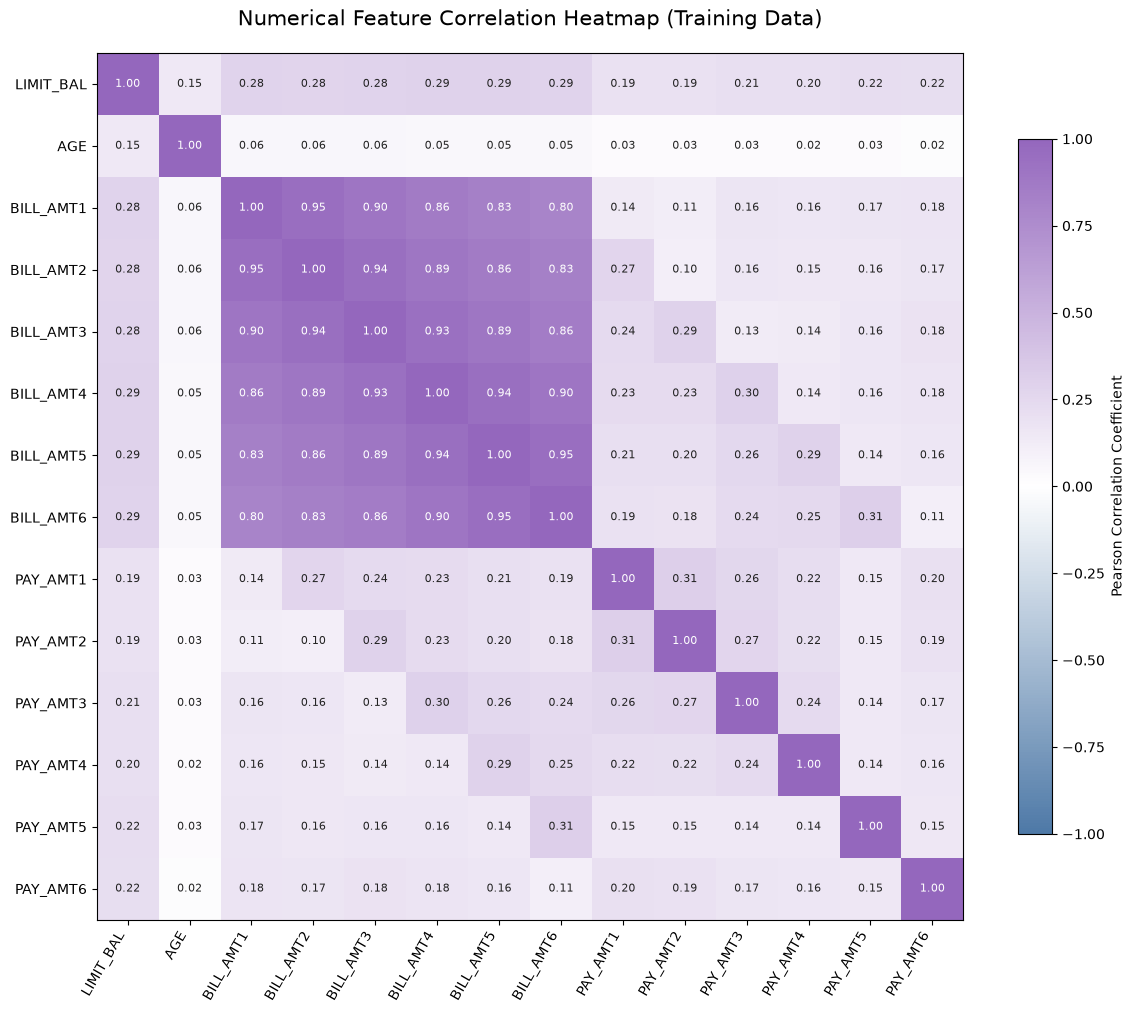

Saved: figures/eda_correlation_heatmap.png
Saved: results/eda_correlation_matrix.csv


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

# 1. Select numerical features according to M2's contract
numeric_features = (
    ["LIMIT_BAL", "AGE"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)

# 2. Calculate Pearson correlation matrix
corr_matrix = X_train[numeric_features].corr(
    method="pearson"
)

display(corr_matrix.round(2))

# 3. Create professional blue-white-purple colour map
cmap = LinearSegmentedColormap.from_list(
    "professional_correlation",
    ["#4E79A7", "#FFFFFF", "#9467BD"]
)

text_color = (
    "white" if abs(value) >= 0.75
    else "#222222"
)

# 4. Plot correlation heatmap
fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    corr_matrix,
    cmap=cmap,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(numeric_features)))
ax.set_yticks(range(len(numeric_features)))

ax.set_xticklabels(
    numeric_features,
    rotation=60,
    ha="right"
)

ax.set_yticklabels(numeric_features)

# 5. Display correlation values
for i in range(len(numeric_features)):
    for j in range(len(numeric_features)):

        value = corr_matrix.iloc[i, j]

        text_color = (
            "white" if abs(value) >= 0.75
            else "#222222"
        )

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color=text_color
        )

# 6. Add title and colour legend
ax.set_title(
    "Numerical Feature Correlation Heatmap (Training Data)",
    fontsize=15,
    pad=20
)

fig.colorbar(
    im,
    ax=ax,
    label="Pearson Correlation Coefficient",
    shrink=0.8
)

plt.tight_layout()

# 7. Save evidence
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

corr_matrix.to_csv(
    "results/eda_correlation_matrix.csv"
)

plt.show()

print("Saved: figures/eda_correlation_heatmap.png")
print("Saved: results/eda_correlation_matrix.csv")

## 10. Outlier Analysis Using the IQR Method

**Objective:** To identify potential outliers in numerical features using the Interquartile Range (IQR) method and evaluate the extent of extreme values.

**Features:**
- LIMIT_BAL
- AGE
- BILL_AMT1–6
- PAY_AMT1–6

**Method:** IQR (Interquartile Range)

**Evidence:**
- `results/eda_outlier_summary.csv`
- `figures/eda_outlier_analysis.png`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation

**Note:** Outliers are identified for exploratory analysis only. No records are removed or modified, and all calculations use the training dataset.

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,LIMIT_BAL,50000.00,240000.00,190000.00,-235000.00,525000.00,136,0.57
1,AGE,28.00,41.00,13.00,8.50,60.50,214,0.89
3,BILL_AMT2,2989.75,63992.75,61003.00,-88514.75,155497.25,1898,7.91
2,BILL_AMT1,3513.75,66966.50,63452.75,-91665.38,162145.62,1899,7.91
4,BILL_AMT3,2652.00,60033.75,57381.75,-83420.62,146106.38,1980,8.25
10,PAY_AMT3,390.00,4580.50,4190.50,-5895.75,10866.25,2084,8.68
5,BILL_AMT4,2332.00,54386.50,52054.50,-75749.75,132468.25,2104,8.77
7,BILL_AMT6,1225.00,48977.25,47752.25,-70403.38,120605.62,2159,9.00
8,PAY_AMT1,1000.00,5018.25,4018.25,-5027.38,11045.62,2170,9.04
9,PAY_AMT2,840.00,5000.00,4160.00,-5400.00,11240.00,2183,9.10


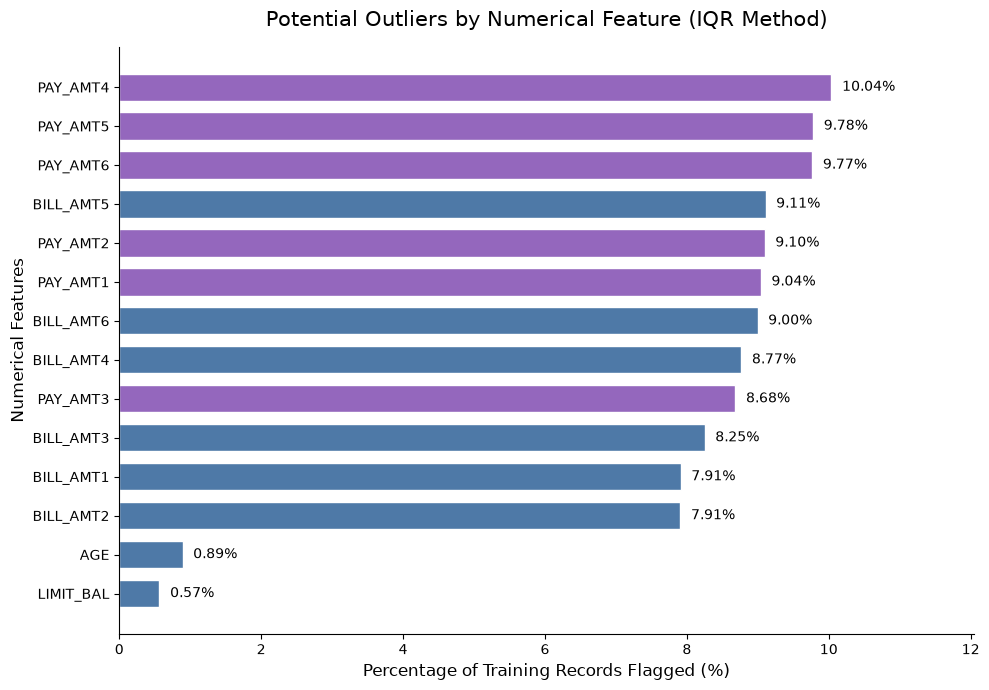

Saved: results/eda_outlier_summary.csv
Saved: figures/eda_outlier_analysis.png


In [21]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Select numerical features
numeric_features = (
    ["LIMIT_BAL", "AGE"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)

# 2. Calculate outliers using the IQR method
outlier_results = []

for feature in numeric_features:

    values = X_train[feature]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())
    outlier_percentage = (
        outlier_count / len(values) * 100
    )

    outlier_results.append({
        "feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage": outlier_percentage
    })

# 3. Convert results into a DataFrame
outlier_summary = pd.DataFrame(
    outlier_results
).sort_values(
    "outlier_percentage",
    ascending=True
)

display(outlier_summary.round(2))

# 4. Save summary CSV
Path("results").mkdir(exist_ok=True)

outlier_summary.to_csv(
    "results/eda_outlier_summary.csv",
    index=False
)

# 5. Create professional outlier comparison chart
fig, ax = plt.subplots(figsize=(10, 7))

colors = [
    "#9467BD" if feature.startswith("PAY_AMT")
    else "#4E79A7"
    for feature in outlier_summary["feature"]
]

bars = ax.barh(
    outlier_summary["feature"],
    outlier_summary["outlier_percentage"],
    color=colors,
    edgecolor="white",
    height=0.7
)

# 6. Add percentage labels
for bar, value in zip(
    bars,
    outlier_summary["outlier_percentage"]
):
    ax.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=10
    )

ax.set_xlim(
    0,
    max(
        outlier_summary["outlier_percentage"].max() * 1.2,
        5
    )
)

ax.set_title(
    "Potential Outliers by Numerical Feature (IQR Method)",
    fontsize=15,
    pad=15
)

ax.set_xlabel(
    "Percentage of Training Records Flagged (%)",
    fontsize=12
)

ax.set_ylabel("Numerical Features", fontsize=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# 7. Save figure
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_outlier_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/eda_outlier_summary.csv")
print("Saved: figures/eda_outlier_analysis.png")
